In [1]:
REPO = "/kaggle/working/ComputerVisionAndImageProcessing"
BRANCH = "pro1-sr-experiments"
!git clone -q -b {BRANCH} https://github.com/nataliachoszczyk/ComputerVisionAndImageProcessing.git {REPO} 2>/dev/null || (git -C {REPO} fetch -q origin {BRANCH} && git -C {REPO} checkout -q {BRANCH} && git -C {REPO} pull -q origin {BRANCH})
%cd {REPO}/01-image-modification

/kaggle/working/ComputerVisionAndImageProcessing/01-image-modification


In [2]:
from pathlib import Path

if not Path("/tmp/div2k").exists():
    !wget -q --show-progress -P /tmp http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip
    !wget -q --show-progress -P /tmp http://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip
    !unzip -q /tmp/DIV2K_train_HR.zip -d /tmp/div2k
    !unzip -q /tmp/DIV2K_valid_HR.zip -d /tmp/div2k
    !rm /tmp/DIV2K_*.zip

print(len(list(Path("/tmp/div2k").rglob("*.png"))))

DIV2K_train_HR.zip  100%[===================>]   3.29G  30.1MB/s    in 1m 56s  
DIV2K_valid_HR.zip  100%[===================>] 428.19M  29.7MB/s    in 15s     
900


In [3]:
from data import cut_patches
from sr_data_preparation import make_lr_patches

PATCHES = "/tmp/patches"

if not Path(PATCHES).exists():
    cut_patches("/tmp/div2k", PATCHES)
    make_lr_patches(PATCHES)

train:   0%|          | 0/750 [00:00<?, ?it/s]

val:   0%|          | 0/50 [00:00<?, ?it/s]

test:   0%|          | 0/100 [00:00<?, ?it/s]

train/lr_x4:   0%|          | 0/30000 [00:00<?, ?it/s]

val/lr_x4:   0%|          | 0/1757 [00:00<?, ?it/s]

test/lr_x4:   0%|          | 0/3598 [00:00<?, ?it/s]

train/lr_x8:   0%|          | 0/30000 [00:00<?, ?it/s]

val/lr_x8:   0%|          | 0/1757 [00:00<?, ?it/s]

test/lr_x8:   0%|          | 0/3598 [00:00<?, ?it/s]

In [4]:
for split in ["train", "val", "test"]:
    print(split, {d.name: len(list(d.glob("*.png"))) for d in sorted(Path(PATCHES, split).iterdir())})

train {'lr_x4': 30000, 'lr_x8': 30000, 'original': 30000}
val {'lr_x4': 1757, 'lr_x8': 1757, 'original': 1757}
test {'lr_x4': 3598, 'lr_x8': 3598, 'original': 3598}


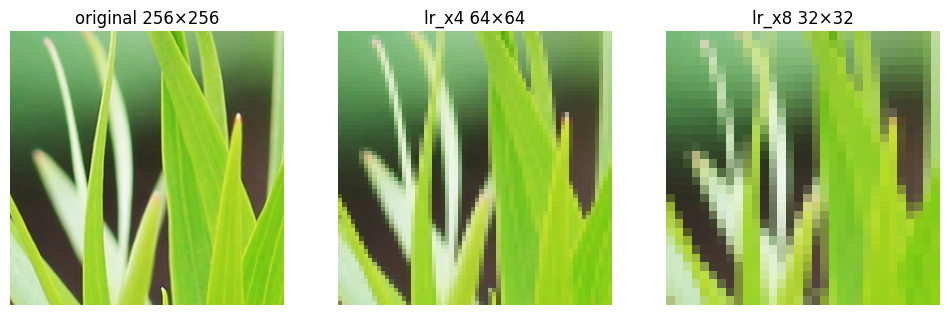

In [5]:
import cv2
import matplotlib.pyplot as plt

name = sorted(Path(PATCHES, "test/original").glob("*.png"))[80].name
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, folder in zip(axes, ["original", "lr_x4", "lr_x8"]):
    img = cv2.cvtColor(cv2.imread(f"{PATCHES}/test/{folder}/{name}"), cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(f"{folder} {img.shape[1]}×{img.shape[0]}")
    ax.axis("off")

In [6]:
!pip install -q lpips

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 2.0 MB/s eta 0:00:00


In [7]:
import shutil
import numpy as np
import pandas as pd
import torch

from data import PatchDataset, PATCH_SIZE
from metrics import evaluate

WORK = Path("/kaggle/working")
device = "cuda" if torch.cuda.is_available() else "cpu"

for f in Path("/kaggle/input").rglob("*"):
    if f.name.startswith(("unet_", "history_", "bicubic_x")):
        shutil.copy(f, WORK)


def bicubic(lr):
    imgs = lr.cpu().permute(0, 2, 3, 1).numpy()
    up = [cv2.resize(img, (PATCH_SIZE, PATCH_SIZE), interpolation=cv2.INTER_CUBIC) for img in imgs]
    return torch.from_numpy(np.stack(up)).permute(0, 3, 1, 2).clamp(0, 1)


results = {}
for scale in [4, 8]:
    csv = WORK / f"bicubic_x{scale}.csv"
    if not csv.exists():
        test = PatchDataset(f"{PATCHES}/test/lr_x{scale}", f"{PATCHES}/test/original")
        evaluate(bicubic, test, device).to_csv(csv)
    results[f"bicubic_x{scale}"] = pd.read_csv(csv, index_col=0)

pd.DataFrame({name: df.mean() for name, df in results.items()}).T

,PSNR,SSIM,LPIPS,SNE
bicubic_x4,29.577713,0.770909,0.382905,642.477559
bicubic_x8,26.619552,0.627290,0.557436,1158.917273


In [8]:
from model import UNet

for upsample in ["bicubic", "learned"]:
    model = UNet(scale=4, upsample=upsample)
    print(upsample, model(torch.rand(2, 3, 64, 64)).shape, sum(p.numel() for p in model.parameters()))

bicubic torch.Size([2, 3, 256, 256]) 1925667
learned torch.Size([2, 3, 256, 256]) 1927011


In [9]:
from training import train

# name -> (upsampling, width); files: <name>_x<scale>.pt, history<name without "unet">_x<scale>.csv
MODELS = {
    "unet": ("bicubic", 32),
    "unet_learned": ("learned", 32),
    "unet_wide": ("bicubic", 64),
    "unet_learned_wide": ("learned", 64),
}
LABELS = {
    "bicubic": "bicubic interpolation (baseline)",
    "unet": "UNet c=32, bicubic input",
    "unet_learned": "UNet c=32, learned upsampling",
    "unet_wide": "UNet c=64, bicubic input",
    "unet_learned_wide": "UNet c=64, learned upsampling",
}
# models trained in this run (others are only loaded from Input, if available)
TRAIN = ["unet_learned"]

checkpoint = lambda name, scale: WORK / f"{name}_x{scale}.pt"
history_csv = lambda name, scale: WORK / f"history{name[4:]}_x{scale}.csv"

# experiment 1: c=32 models, trained here one after another
for name, (upsample, width) in MODELS.items():
    for scale in [4, 8]:
        if name not in TRAIN or width != 32 or checkpoint(name, scale).exists():
            continue
        train_set = PatchDataset(f"{PATCHES}/train/lr_x{scale}", f"{PATCHES}/train/original")
        val_set = PatchDataset(f"{PATCHES}/val/lr_x{scale}", f"{PATCHES}/val/original")
        history = train(UNet(scale=scale, upsample=upsample), train_set, val_set, checkpoint(name, scale), epochs=25)
        history.to_csv(history_csv(name, scale), index=False)

In [10]:
# experiment 2: wider UNet (c=64), both upsampling variants
# ~11.5 min/epoch on a T4, so x4 runs on GPU 0 and x8 on GPU 1 in parallel (sr_training.py, like denoise_training.py)
import os
import subprocess
import sys

n_gpus = torch.cuda.device_count()
procs = []
for i, scale in enumerate([4, 8]):
    cmds = []
    for name, (upsample, width) in MODELS.items():
        if name in TRAIN and width == 64 and not checkpoint(name, scale).exists():
            cmds.append(f"{sys.executable} -u sr_training.py {PATCHES} {scale} "
                        f"--upsample {upsample} --width {width} --epochs 25 --out {WORK}")
    if not cmds:
        continue
    log = WORK / f"train_wide_x{scale}.log"
    env = {**os.environ, "CUDA_VISIBLE_DEVICES": str(i % max(n_gpus, 1))}
    proc = subprocess.Popen(" && ".join(cmds), shell=True, env=env, stdout=open(log, "w"), stderr=subprocess.STDOUT)
    procs.append((log, proc))
    if n_gpus < 2:
        proc.wait()

for log, proc in procs:
    proc.wait()
    print(f"{log.name} (exit code {proc.returncode})\n" + log.read_text()[-2500:])

In [11]:
trained = [name for name in MODELS if all(checkpoint(name, s).exists() for s in [4, 8])]

for name in trained:
    upsample, width = MODELS[name]
    for scale in [4, 8]:
        model = UNet(scale=scale, c=width, upsample=upsample)
        model.load_state_dict(torch.load(checkpoint(name, scale), map_location=device))
        model.to(device).eval()
        test = PatchDataset(f"{PATCHES}/test/lr_x{scale}", f"{PATCHES}/test/original")
        results[f"{name}_x{scale}"] = evaluate(model, test, device)

rows = [(m, s) for s in [4, 8] for m in ["bicubic"] + trained]
table = pd.DataFrame({f"{LABELS[m]} x{s}": results[f"{m}_x{s}"].mean() for m, s in rows}).T
table.index.name = "method"
table.to_csv(WORK / "results.csv")
table.round(4)

  0%|          | 0/225 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth



  0%|          | 0.00/233M [00:00<?, ?B/s]
  3%|▎         | 8.00M/233M [00:00<00:02, 83.4MB/s]
 12%|█▏        | 26.9M/233M [00:00<00:01, 150MB/s] 
 21%|██        | 48.1M/233M [00:00<00:01, 183MB/s]
 30%|██▉       | 69.2M/233M [00:00<00:00, 198MB/s]
 40%|███▉      | 93.1M/233M [00:00<00:00, 217MB/s]
 50%|████▉     | 116M/233M [00:00<00:00, 226MB/s] 
 60%|██████    | 140M/233M [00:00<00:00, 233MB/s]
 70%|███████   | 164M/233M [00:00<00:00, 238MB/s]
 81%|████████  | 188M/233M [00:00<00:00, 242MB/s]
 91%|█████████ | 211M/233M [00:01<00:00, 228MB/s]
100%|██████████| 233M/233M [00:01<00:00, 217MB/s]


  0%|          | 0/225 [00:00<?, ?it/s]

  0%|          | 0/225 [00:00<?, ?it/s]

... (2 outputs left out)

  0%|          | 0/225 [00:00<?, ?it/s]

  0%|          | 0/225 [00:00<?, ?it/s]

  0%|          | 0/225 [00:00<?, ?it/s]

,PSNR,SSIM,LPIPS,SNE
method,,,,
bicubic interpolation (baseline) x4,29.5777,0.7709,0.3829,642.4776
"UNet c=32, bicubic input x4",30.9966,0.8168,0.2633,480.4622
"UNet c=32, learned upsampling x4",30.5080,0.8083,0.2705,515.5382
"UNet c=64, bicubic input x4",31.0806,0.8189,0.2591,474.8686
"UNet c=64, learned upsampling x4",30.8273,0.8157,0.2614,490.8125
bicubic interpolation (baseline) x8,26.6196,0.6273,0.5574,1158.9173
"UNet c=32, bicubic input x8",27.6109,0.6746,0.4248,965.9471
"UNet c=32, learned upsampling x8",27.3165,0.6679,0.4275,987.1158
"UNet c=64, bicubic input x8",27.6471,0.6766,0.4234,962.5230


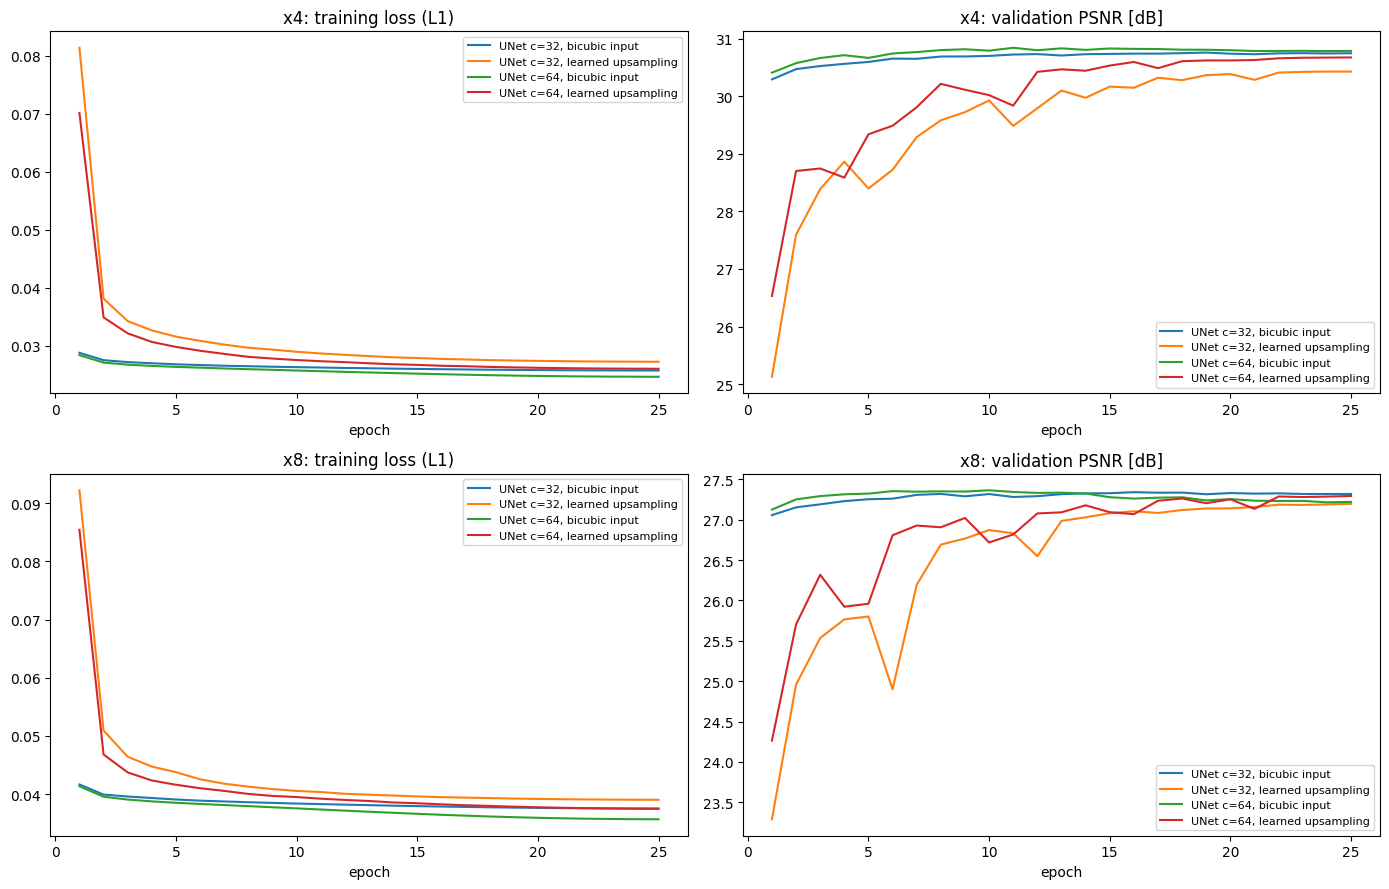

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row, scale in zip(axes, [4, 8]):
    for name in trained:
        h = pd.read_csv(history_csv(name, scale))
        row[0].plot(h.epoch, h.train_loss, label=LABELS[name])
        row[1].plot(h.epoch, h.val_psnr, label=LABELS[name])
    row[0].set(title=f"x{scale}: training loss (L1)", xlabel="epoch")
    row[1].set(title=f"x{scale}: validation PSNR [dB]", xlabel="epoch")
    for ax in row:
        ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(WORK / "learning_curves.png", dpi=150, bbox_inches="tight")

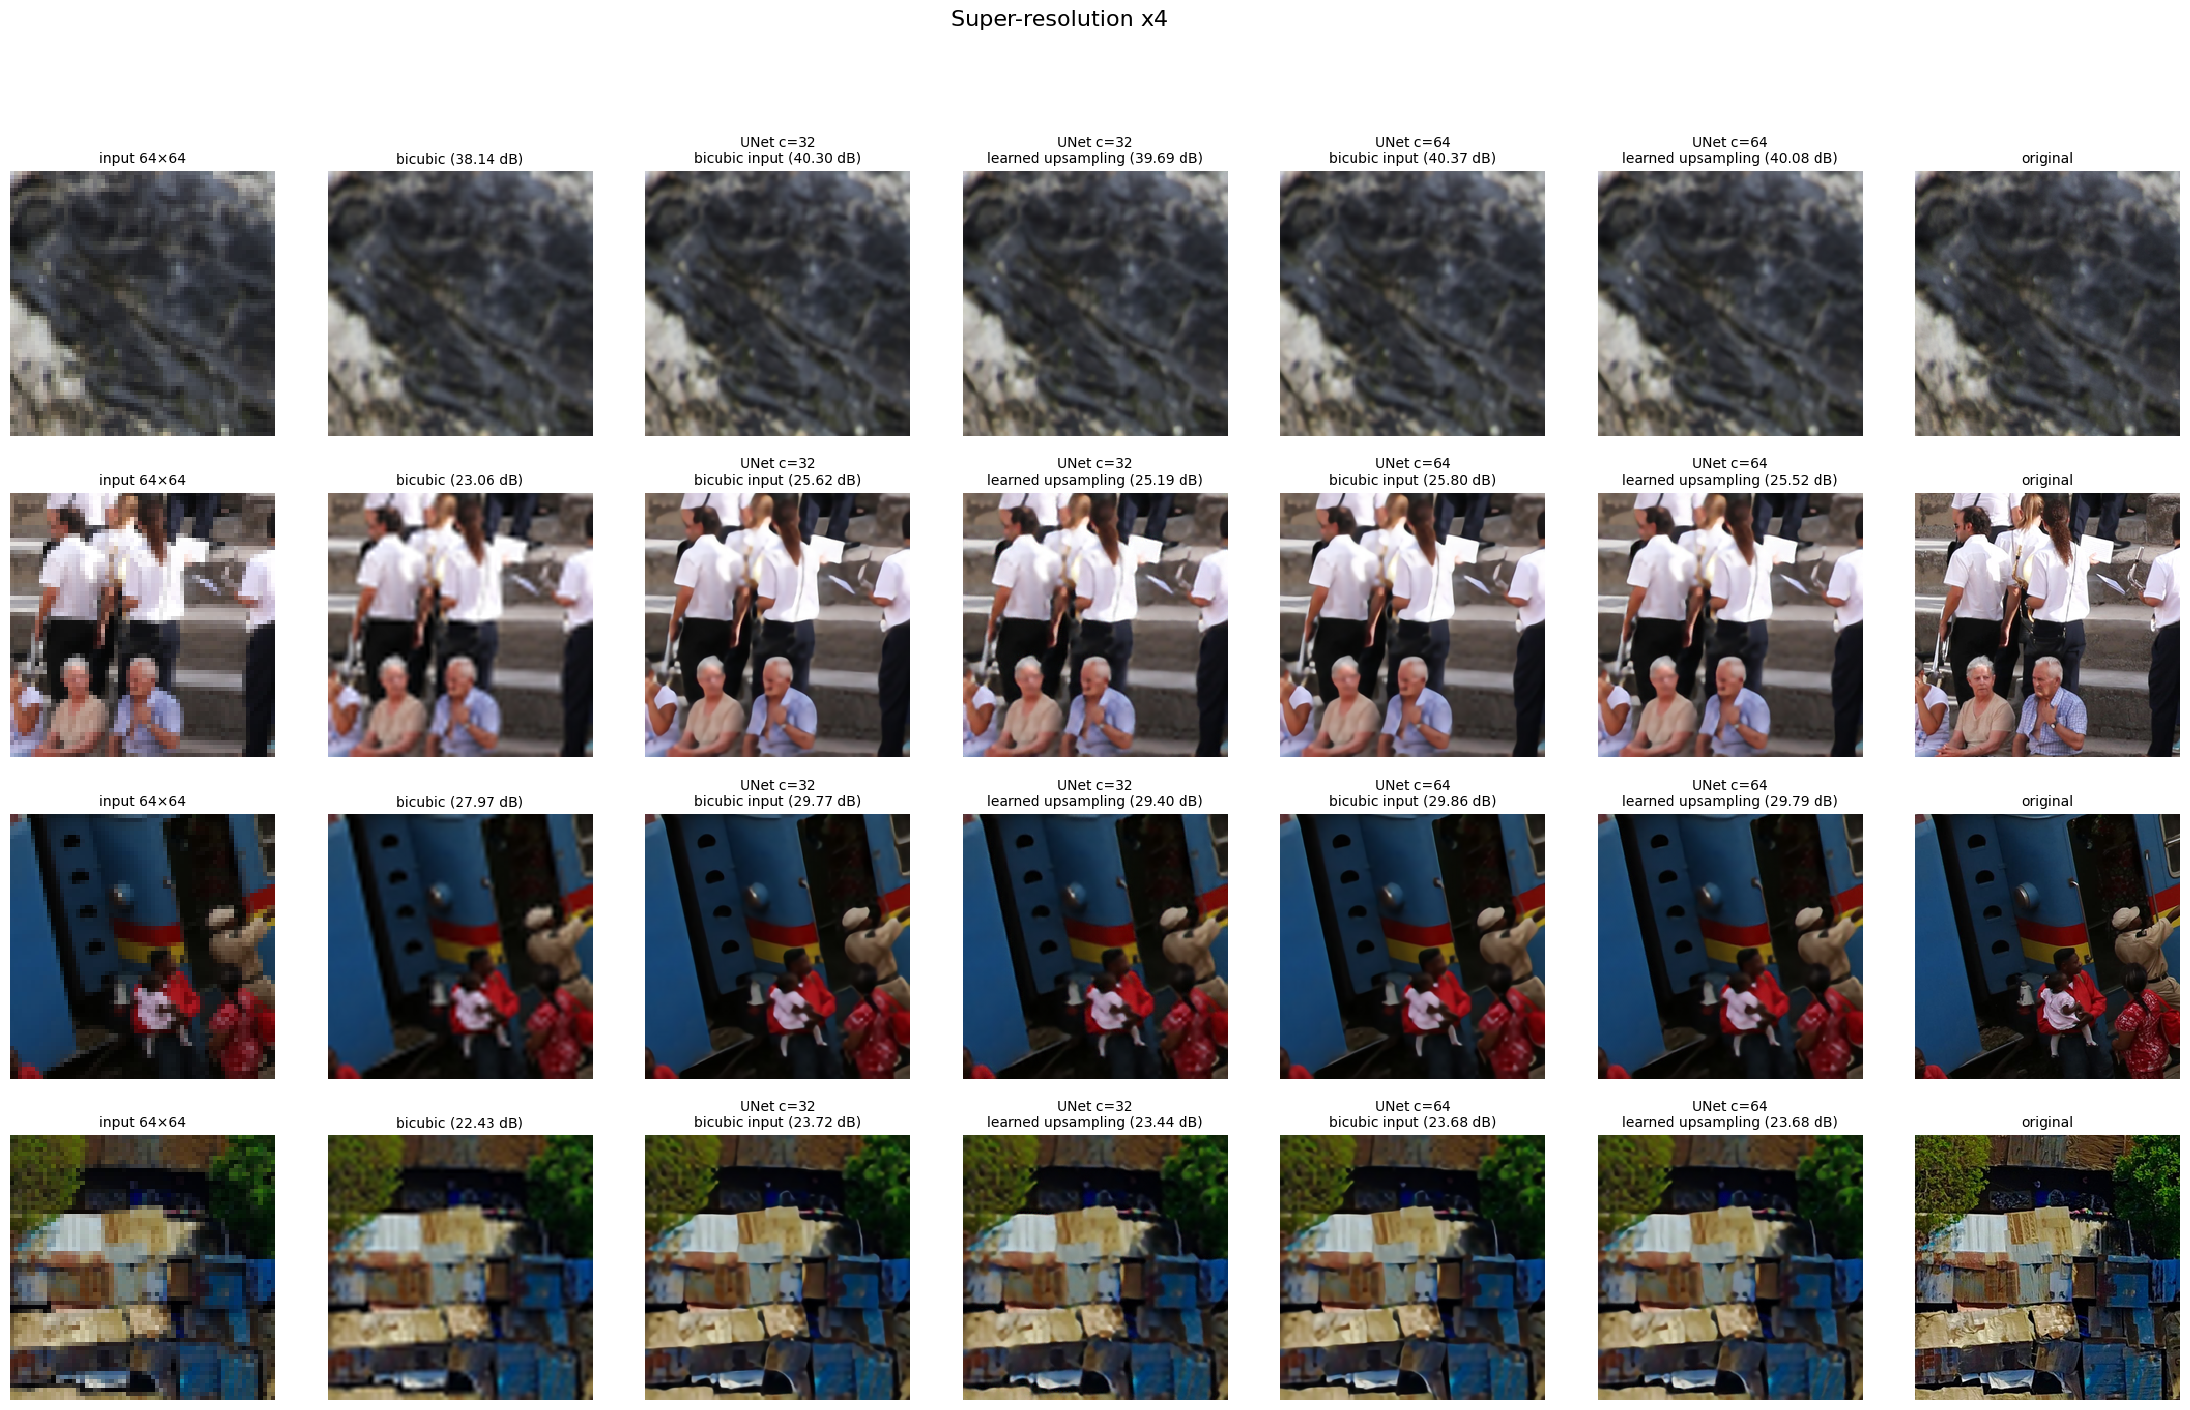

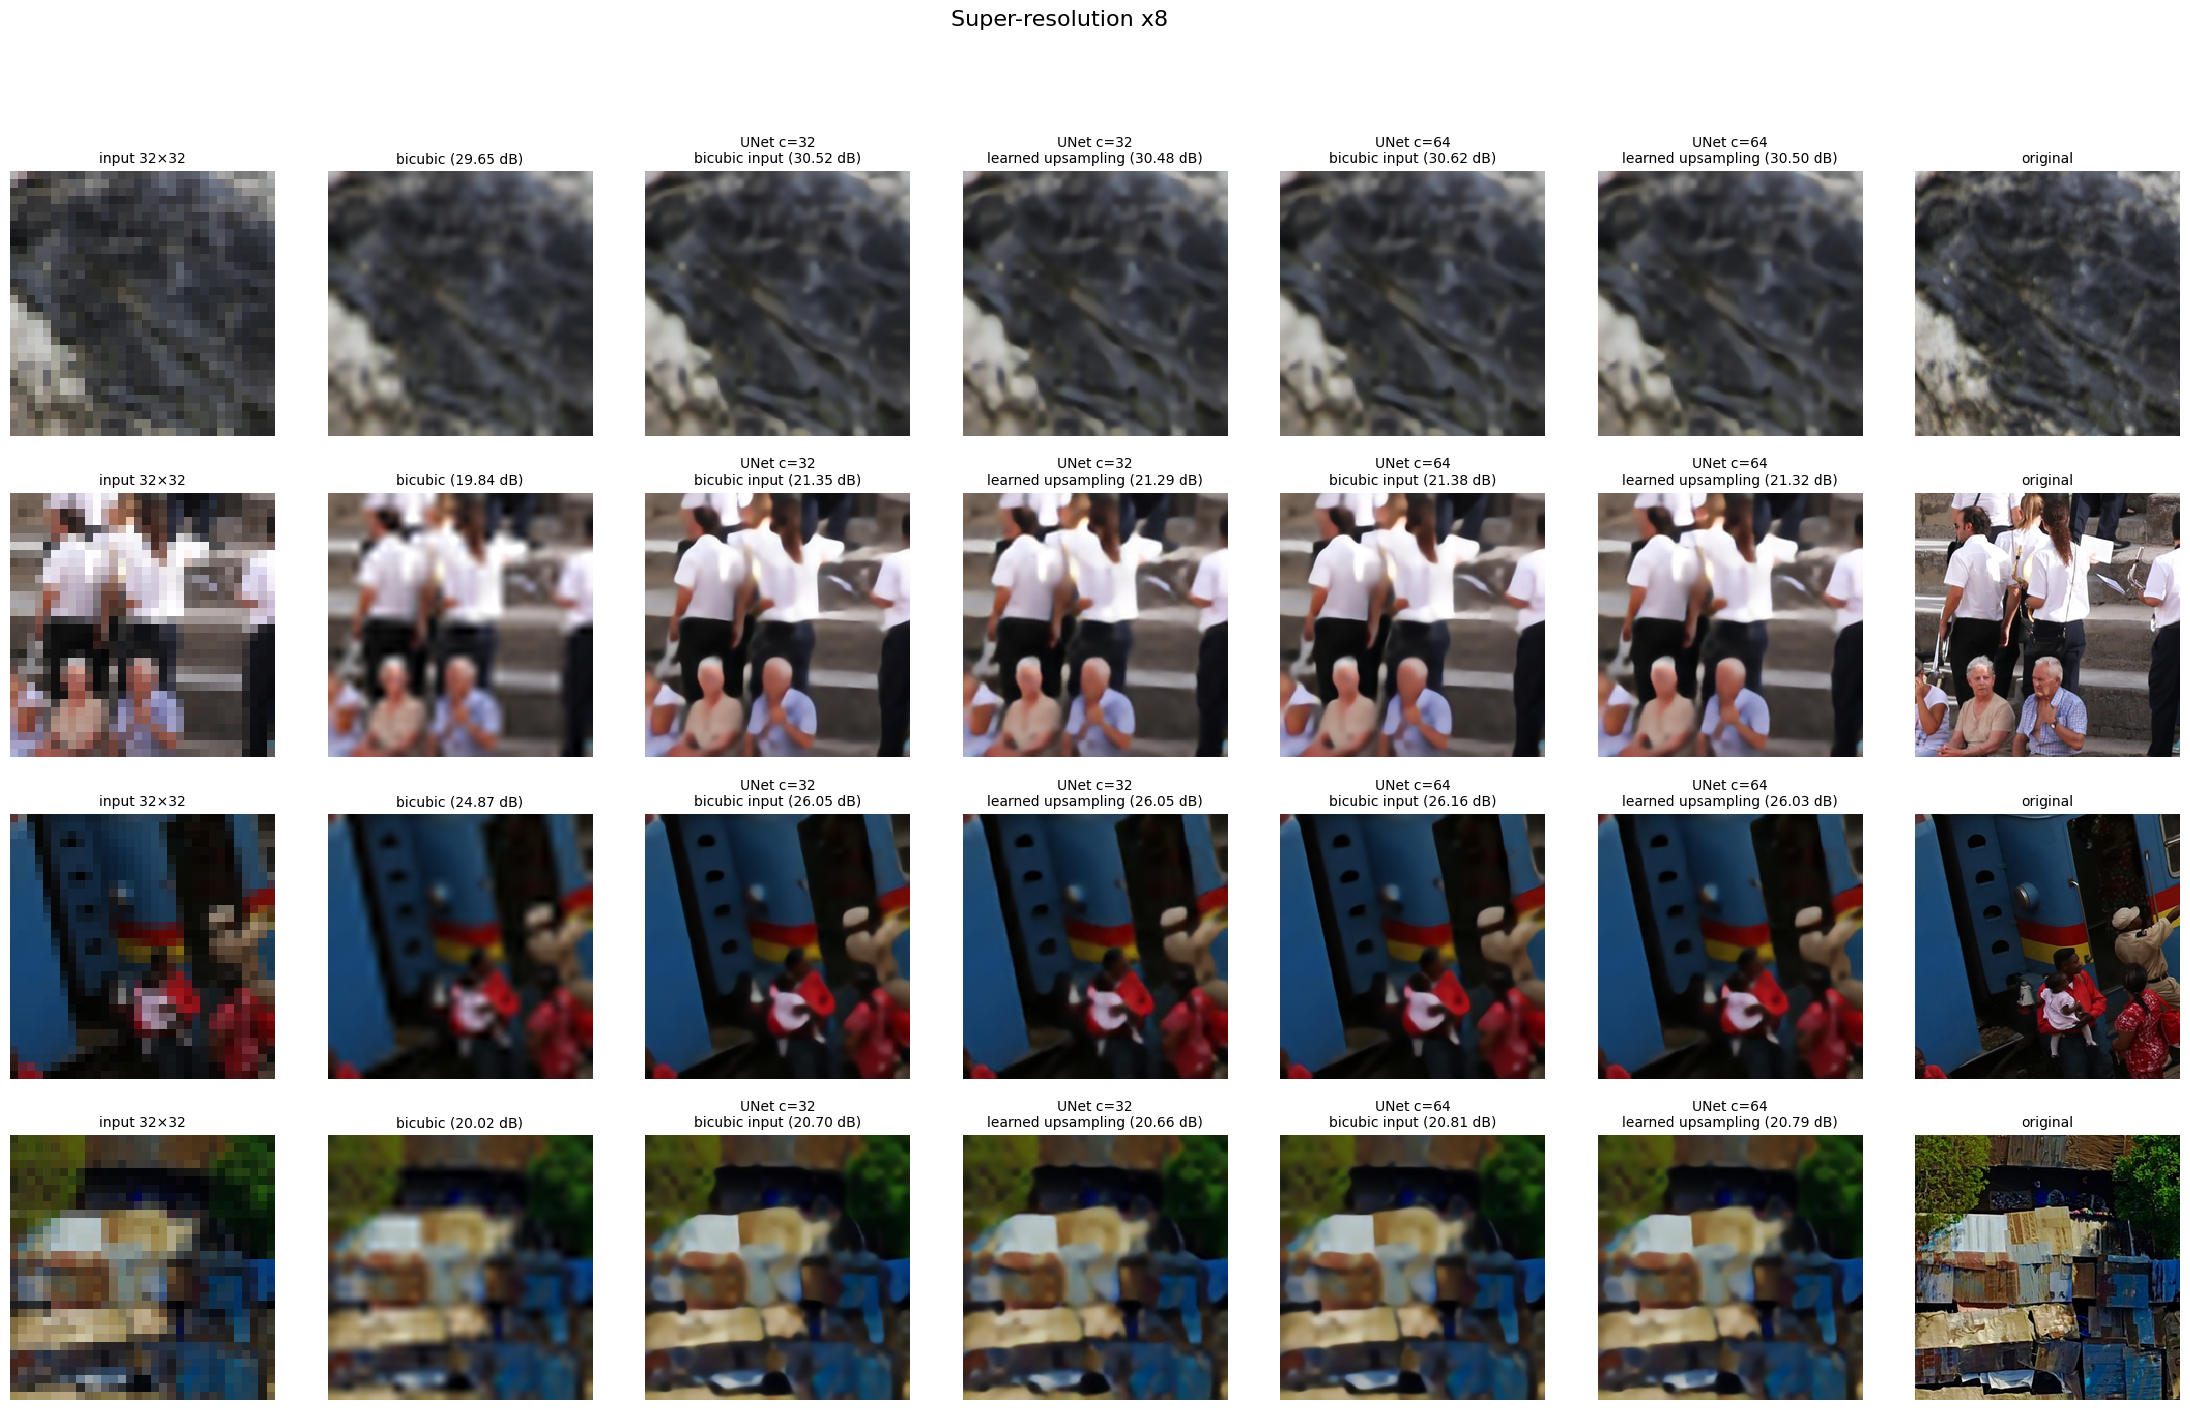

In [13]:
from data import load_image
from metrics import psnr

names = sorted(p.name for p in Path(PATCHES, "test/original").glob("*.png"))[::900]

for scale in [4, 8]:
    models = {}
    for name in trained:
        upsample, width = MODELS[name]
        m = UNet(scale=scale, c=width, upsample=upsample)
        m.load_state_dict(torch.load(checkpoint(name, scale), map_location="cpu"))
        models[name] = m.eval()

    n_cols = len(models) + 3
    fig, axes = plt.subplots(len(names), n_cols, figsize=(4 * n_cols, 4 * len(names)))
    for row, patch in zip(axes, names):
        lr = load_image(f"{PATCHES}/test/lr_x{scale}/{patch}")[None]
        hr = load_image(f"{PATCHES}/test/original/{patch}")[None]
        with torch.no_grad():
            images = {f"input {256 // scale}×{256 // scale}": lr, "bicubic": bicubic(lr)}
            for name, m in models.items():
                images[LABELS[name].replace(", ", "\n")] = m(lr).clamp(0, 1)
            images["original"] = hr
        for ax, (title, img) in zip(row, images.items()):
            if title != "original" and not title.startswith("input"):
                title += f" ({psnr(img, hr).item():.2f} dB)"
            ax.imshow(img[0].permute(1, 2, 0).numpy(), interpolation="nearest")
            ax.set_title(title, fontsize=10)
            ax.axis("off")
    fig.suptitle(f"Super-resolution x{scale}", fontsize=16)
    fig.savefig(WORK / f"comparison_x{scale}.png", dpi=100, bbox_inches="tight")